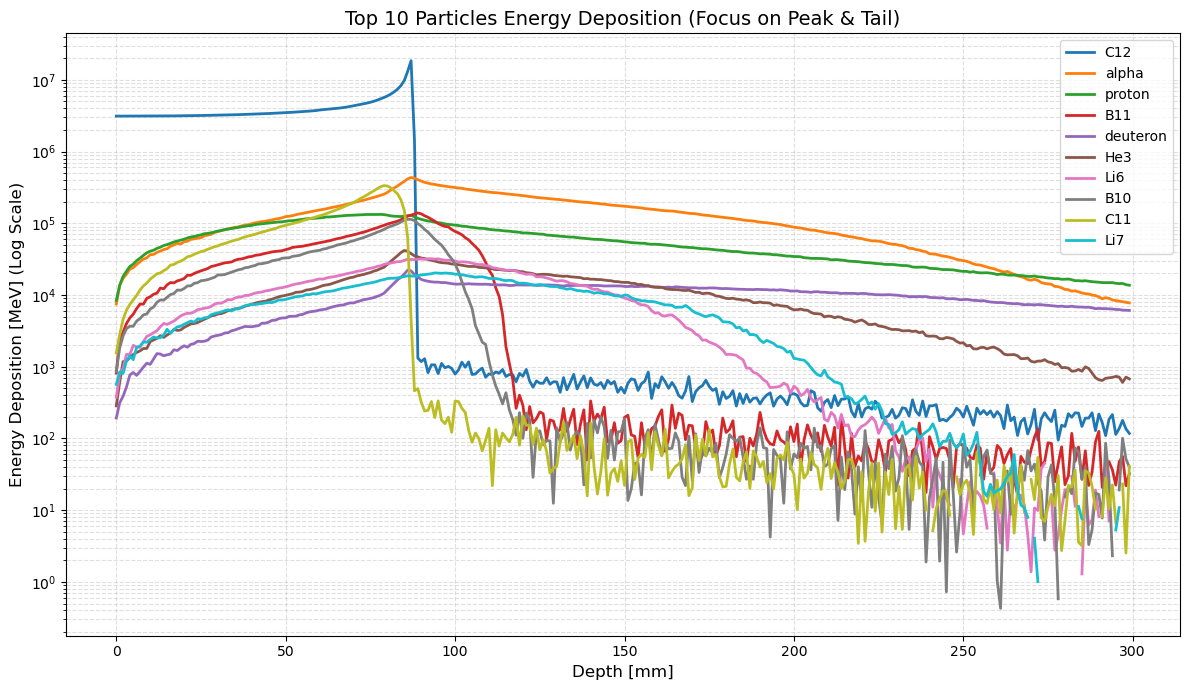

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

# データの読み込み
df = pd.read_csv('carbon2400_QGSP_BIC.csv')

def parse_kv(s):
    if not isinstance(s, str) or not s: return {}
    return {k.split(':')[0].strip(): float(k.split(':')[1].strip()) for k in s.split(';') if ':' in k}

# エネルギー詳細のパースとデータフレーム化
energy_dicts = df['energy_details'].apply(parse_kv)
all_particles = sorted(list(set().union(*(d.keys() for d in energy_dicts))))
energy_df = pd.DataFrame([{p: d.get(p, 0.0) for p in all_particles} for d in energy_dicts])
depth = df['copyNo']

# 80mm以降のエネルギー合計に基づいて上位10粒子を選定
tail_energy = energy_df[depth >= 80].sum()
top_10_particles = tail_energy.sort_values(ascending=False).head(10).index.tolist()

# プロット作成
plt.figure(figsize=(12, 7))
cmap = plt.get_cmap('tab10') # 10色用のカラーマップ
colors = cmap(np.linspace(0, 1, len(top_10_particles)))

for i, p in enumerate(top_10_particles):
    y = energy_df[p].replace(0, np.nan)
    plt.plot(depth, y, label=p, color=colors[i], lw=2)

plt.yscale('log')
plt.xlabel('Depth [mm]', fontsize=12)
plt.ylabel('Energy Deposition [MeV] (Log Scale)', fontsize=12)
plt.title('Top 10 Particles Energy Deposition (Focus on Peak & Tail)', fontsize=14)
plt.legend(loc='upper right')
plt.grid(True, which="both", ls="--", alpha=0.4)
plt.tight_layout()

# 保存
plt.savefig('top10_energy_deposition.png', dpi=300)
plt.show()